<a href="https://colab.research.google.com/github/sanchari1/privacy-utility-tradeoff/blob/Test/privacy_utility_tradeoff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

base = "/content/drive/MyDrive/privacy-project"
os.makedirs(base + "/data", exist_ok=True)
os.makedirs(base + "/figures", exist_ok=True)
print("Folders ready:", os.listdir(base))

Folders ready: ['data', 'figures']


In [4]:
import pandas as pd
from sklearn.datasets import fetch_openml

adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame
print(df.shape)
print(df.columns.tolist())

(48842, 15)
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'class']


In [5]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [6]:
print("Missing values per column:")
print(df.isna().sum())

df = df.dropna().reset_index(drop=True)
print("Rows after removing missing:", df.shape[0])

Missing values per column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
class                0
dtype: int64
Rows after removing missing: 45222


In [7]:
df.to_csv(base + "/data/adult_clean.csv", index=False)
print("Saved")

Saved


## Threat model
- Quasi-identifiers: age, sex, race, marital-status, native-country
- Sensitive attribute: class (income above or below $50K)
- Threat: someone who knows these five facts about a person tries to find their row and learn their income.

In [8]:
import matplotlib.pyplot as plt

qi = ["age", "sex", "race", "marital-status", "native-country"]

In [9]:
group_size = df.groupby(qi)["class"].transform("size")

/tmp/ipykernel_424/4238998701.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_size = df.groupby(qi)["class"].transform("size")


In [10]:
print("Records:", len(df))
print("Unique combinations:", df.groupby(qi).ngroups)
print("Records unique in the dataset (k=1):", (group_size == 1).sum(),
      f"({(group_size == 1).mean():.1%})")
print("Records with k<5:", (group_size < 5).sum(),
      f"({(group_size < 5).mean():.1%})")
print("Smallest group size (k):", group_size.min())

Records: 45222
Unique combinations: 4304
Records unique in the dataset (k=1): 2539 (5.6%)
Records with k<5: 5043 (11.2%)
Smallest group size (k): 1


/tmp/ipykernel_424/2815256776.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("Unique combinations:", df.groupby(qi).ngroups)


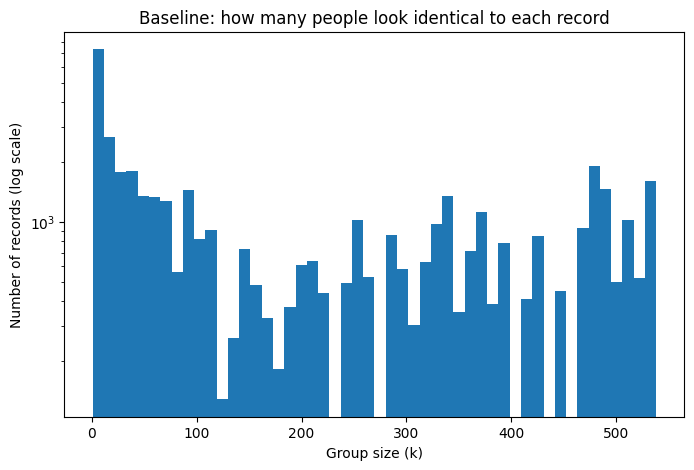

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(group_size, bins=50)
plt.yscale("log")
plt.xlabel("Group size (k)")
plt.ylabel("Number of records (log scale)")
plt.title("Baseline: how many people look identical to each record")
plt.savefig(base + "/figures/baseline_group_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
qi_short = ["age", "sex", "race", "marital-status"]

group_size_short = df.groupby(qi_short, observed=True)["class"].transform("size")

print("Records unique (k=1):", (group_size_short == 1).sum(),
      f"({(group_size_short == 1).mean():.1%})")

Records unique (k=1): 555 (1.2%)


Removing native-country reduced unique records from 5.6% (2,539) to 1.2% (555). Detailed attributes with many rare values, like country, make people easy to single out, so generalising them should reduce risk.

In [14]:
def risk_summary(data, cols, label):
    gs = data.groupby(cols, observed=True)["class"].transform("size")
    print(label)
    print("  Unique combinations:", data.groupby(cols, observed=True).ngroups)
    print("  Unique records (k=1):", (gs == 1).sum(), f"({(gs == 1).mean():.1%})")
    print("  Records with k<5:", (gs < 5).sum(), f"({(gs < 5).mean():.1%})")
    print("  Smallest k:", gs.min())
    return gs

qi = ["age", "sex", "race", "marital-status", "native-country"]
gs_original = risk_summary(df, qi, "ORIGINAL DATA")

ORIGINAL DATA
  Unique combinations: 4304
  Unique records (k=1): 2539 (5.6%)
  Records with k<5: 5043 (11.2%)
  Smallest k: 1


In [15]:
import numpy as np

df_g = df.copy()

# 1. Age: exact number to a band
df_g["age"] = pd.to_numeric(df_g["age"])
df_g["age_band"] = pd.cut(
    df_g["age"],
    bins=[0, 24, 34, 44, 54, 64, 120],
    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# 2. Country: 41 countries to two groups
df_g["country_group"] = np.where(
    df_g["native-country"].astype(str) == "United-States", "United-States", "Other"
)

# 3. Marital status: 7 values to 3
marital_map = {
    "Married-civ-spouse": "Married",
    "Married-spouse-absent": "Married",
    "Married-AF-spouse": "Married",
    "Divorced": "Previously married",
    "Separated": "Previously married",
    "Widowed": "Previously married",
    "Never-married": "Never married",
}
df_g["marital_group"] = df_g["marital-status"].astype(str).map(marital_map)

print(df_g[["age", "age_band", "native-country", "country_group",
            "marital-status", "marital_group"]].head(8))
print("Missing marital_group values:", df_g["marital_group"].isna().sum())

   age age_band native-country  country_group      marital-status  \
0   25    25-34  United-States  United-States       Never-married   
1   38    35-44  United-States  United-States  Married-civ-spouse   
2   28    25-34  United-States  United-States  Married-civ-spouse   
3   44    35-44  United-States  United-States  Married-civ-spouse   
4   34    25-34  United-States  United-States       Never-married   
5   63    55-64  United-States  United-States  Married-civ-spouse   
6   24      <25  United-States  United-States       Never-married   
7   55    55-64  United-States  United-States  Married-civ-spouse   

   marital_group  
0  Never married  
1        Married  
2        Married  
3        Married  
4  Never married  
5        Married  
6  Never married  
7        Married  
Missing marital_group values: 0


In [16]:
qi_g = ["age_band", "sex", "race", "marital_group", "country_group"]
gs_generalised = risk_summary(df_g, qi_g, "AFTER GENERALISATION")

AFTER GENERALISATION
  Unique combinations: 296
  Unique records (k=1): 37 (0.1%)
  Records with k<5: 176 (0.4%)
  Smallest k: 1


In [17]:
K = 5
df_safe = df_g[gs_generalised >= K].copy()

lost = len(df_g) - len(df_safe)
print(f"Records removed: {lost} ({lost / len(df_g):.2%} of the data)")
print("Records remaining:", len(df_safe))

gs_safe = risk_summary(df_safe, qi_g, "AFTER GENERALISATION + SUPPRESSION")

Records removed: 176 (0.39% of the data)
Records remaining: 45046
AFTER GENERALISATION + SUPPRESSION
  Unique combinations: 211
  Unique records (k=1): 0 (0.0%)
  Records with k<5: 0 (0.0%)
  Smallest k: 5


In [18]:
df_safe.to_csv(base + "/data/adult_k5.csv", index=False)
print("Saved")

Saved


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

other = ["education-num", "hours-per-week", "capital-gain", "capital-loss"]

# Original features (detailed)
df_orig = df.copy()
df_orig["age"] = pd.to_numeric(df_orig["age"])
features_orig = ["age", "sex", "race", "marital-status", "native-country"] + other

# Protected features (blurred)
features_safe = ["age_band", "sex", "race", "marital_group", "country_group"] + other

def evaluate(data, feature_cols, label):
    X = pd.get_dummies(data[feature_cols])
    y = (data["class"].astype(str) == ">50K").astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    print(f"{label}: accuracy = {acc:.3f}, F1 = {f1:.3f}")
    return acc, f1

res_orig = evaluate(df_orig, features_orig, "ORIGINAL DATA")
res_safe = evaluate(df_safe, features_safe, "PROTECTED DATA (k=5)")

ORIGINAL DATA: accuracy = 0.840, F1 = 0.651
PROTECTED DATA (k=5): accuracy = 0.844, F1 = 0.650


In [20]:
import numpy as np

# Same people in both versions, so the comparison is fair
same_rows = df_orig.loc[df_safe.index]

def evaluate_repeated(data, feature_cols, label, seeds=(1, 2, 3)):
    X = pd.get_dummies(data[feature_cols])
    y = (data["class"].astype(str) == ">50K").astype(int)
    accs, f1s = [], []
    for s in seeds:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=s, stratify=y
        )
        model = RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=-1)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        accs.append(accuracy_score(y_test, pred))
        f1s.append(f1_score(y_test, pred))
    print(f"{label}: accuracy = {np.mean(accs):.3f} ± {np.std(accs):.3f}, "
          f"F1 = {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")

qi_orig = ["age", "sex", "race", "marital-status", "native-country"]
qi_safe = ["age_band", "sex", "race", "marital_group", "country_group"]

evaluate_repeated(same_rows, features_orig, "ALL FEATURES - original")
evaluate_repeated(df_safe, features_safe, "ALL FEATURES - protected")
evaluate_repeated(same_rows, qi_orig, "QI ONLY - original")
evaluate_repeated(df_safe, qi_safe, "QI ONLY - protected")

ALL FEATURES - original: accuracy = 0.840 ± 0.005, F1 = 0.655 ± 0.013
ALL FEATURES - protected: accuracy = 0.847 ± 0.004, F1 = 0.663 ± 0.013
QI ONLY - original: accuracy = 0.769 ± 0.004, F1 = 0.541 ± 0.006
QI ONLY - protected: accuracy = 0.769 ± 0.005, F1 = 0.524 ± 0.007


In [21]:
y_safe = df_safe["class"].astype(str)
print("Share earning >50K:", round((y_safe == ">50K").mean(), 3))
print("Majority-class baseline accuracy:", round(1 - (y_safe == ">50K").mean(), 3))

tmp = df_safe.assign(cls=y_safe)
grp = tmp.groupby(qi_safe, observed=True)["cls"].agg(["size", "nunique"])
single = grp[grp["nunique"] == 1]

print("Groups:", len(grp))
print("Groups where everyone has the same income class:", len(single))
print("People in those groups:", single["size"].sum(),
      f"({single['size'].sum() / len(df_safe):.1%})")

Share earning >50K: 0.248
Majority-class baseline accuracy: 0.752
Groups: 211
Groups where everyone has the same income class: 47
People in those groups: 643 (1.4%)


After 5-anonymity, 47 of 211 groups (643 people, 1.4%) were homogeneous in income class, so group membership alone reveals the sensitive attribute. k-anonymity protects against being found, not against being learned about.

In [22]:
table = (
    df_safe.groupby(["age_band", "sex", "race"], observed=True)
    .size()
    .reset_index(name="count")
)

print("Cells in the table:", len(table))
print("Cells with count < 5: ", (table["count"] < 5).sum())
print("Cells with count < 10:", (table["count"] < 10).sum())
print("Smallest counts:")
print(table.sort_values("count").head(10))

Cells in the table: 55
Cells with count < 5:  0
Cells with count < 10: 3
Smallest counts:
   age_band     sex                race  count
49      65+  Female  Asian-Pac-Islander      6
47    55-64    Male               Other      7
23    35-44  Female               Other      9
44    55-64    Male  Amer-Indian-Eskimo     10
33    45-54  Female               Other     10
40    55-64  Female  Amer-Indian-Eskimo     14
52      65+    Male  Asian-Pac-Islander     15
41    55-64  Female  Asian-Pac-Islander     19
38    45-54    Male               Other     21
30    45-54  Female  Amer-Indian-Eskimo     23


In [23]:
table = (
    df_safe.groupby(qi_safe, observed=True)
    .size()
    .reset_index(name="count")
)
true = table["count"].to_numpy()
T = 10  # threshold for suppression
rng = np.random.default_rng(42)

print("Cells:", len(table))
print("Cells below", T, ":", (true < T).sum(),
      f"({(true < T).mean():.1%} of cells)")
print("People in those cells:", true[true < T].sum(),
      f"({true[true < T].sum() / true.sum():.1%} of people)")

def report(name, released, true_vals):
    err = np.abs(released - true_vals)
    rel = err / true_vals
    print(f"{name}: mean abs error = {err.mean():.2f}, "
          f"mean relative error = {rel.mean():.1%}, "
          f"max abs error = {err.max():.0f}")

# 1. Rounding to base 5
rounded = (np.round(true / 5) * 5).astype(int)
rounded = np.maximum(rounded, 5)
report("Rounding to base 5", rounded, true)

# 2. Random noise: add a whole number from -2 to +2
noisy = np.maximum(true + rng.integers(-2, 3, size=len(true)), 0)
report("Random noise (-2 to +2)", noisy, true)

# 3. Suppression (only cells >= T are published, exactly)
shown = true >= T
print(f"Suppression: {(~shown).sum()} cells hidden, "
      f"{true[~shown].sum() / true.sum():.1%} of people hidden, "
      f"error on published cells = 0")

Cells: 211
Cells below 10 : 48 (22.7% of cells)
People in those cells: 332 (0.7% of people)
Rounding to base 5: mean abs error = 1.19, mean relative error = 6.2%, max abs error = 2
Random noise (-2 to +2): mean abs error = 1.12, mean relative error = 7.1%, max abs error = 2
Suppression: 48 cells hidden, 0.7% of people hidden, error on published cells = 0


In [24]:
# Build the full grid of all possible cells, including empty ones
dfa = df_safe[qi_safe].astype(str)
full_index = pd.MultiIndex.from_product(
    [sorted(dfa[c].unique()) for c in qi_safe], names=qi_safe
)
counts_full = dfa.groupby(qi_safe).size().reindex(full_index, fill_value=0)

true_full = counts_full.to_numpy()
nonempty = true_full > 0
print("Possible cells:", len(true_full), "| non-empty:", nonempty.sum())

rng = np.random.default_rng(42)
eps_list = [0.05, 0.1, 0.5, 1, 2, 5]
runs = 50

rows = []
for eps in eps_list:
    mae_list, mre_list = [], []
    for _ in range(runs):
        noisy = true_full + rng.laplace(loc=0, scale=1/eps, size=len(true_full))
        noisy = np.maximum(np.round(noisy), 0)
        err = np.abs(noisy - true_full)
        mae_list.append(err[nonempty].mean())
        mre_list.append((err[nonempty] / true_full[nonempty]).mean())
    rows.append((eps, np.mean(mae_list), np.mean(mre_list)))

dp_results = pd.DataFrame(rows, columns=["epsilon", "mean_abs_error", "mean_rel_error"])
dp_results["mean_rel_error"] = (dp_results["mean_rel_error"] * 100).round(1)
dp_results["mean_abs_error"] = dp_results["mean_abs_error"].round(2)
print(dp_results)

Possible cells: 360 | non-empty: 211
   epsilon  mean_abs_error  mean_rel_error
0     0.05           16.97            82.6
1     0.10            9.09            47.2
2     0.50            1.98            11.5
3     1.00            0.96             5.6
4     2.00            0.42             2.5
5     5.00            0.08             0.5


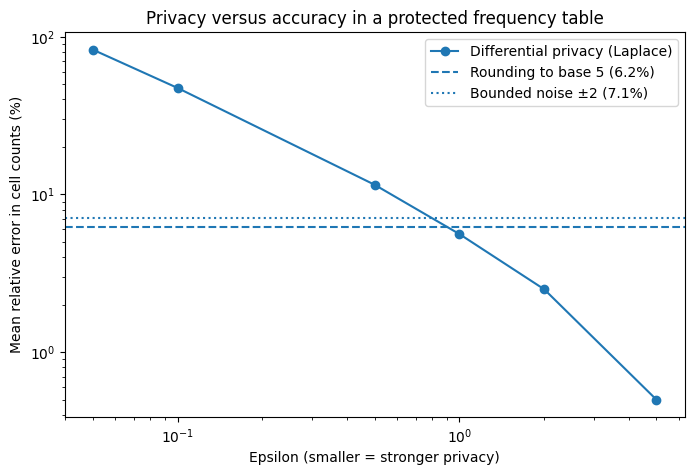

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dp_results["epsilon"], dp_results["mean_rel_error"], marker="o", label="Differential privacy (Laplace)")
ax.axhline(6.2, linestyle="--", label="Rounding to base 5 (6.2%)")
ax.axhline(7.1, linestyle=":", label="Bounded noise ±2 (7.1%)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Epsilon (smaller = stronger privacy)")
ax.set_ylabel("Mean relative error in cell counts (%)")
ax.set_title("Privacy versus accuracy in a protected frequency table")
ax.legend()
plt.savefig(base + "/figures/dp_error_vs_epsilon.png", dpi=150, bbox_inches="tight")
plt.show()